# Single-Image Prediction and Grad-CAM

This research demonstration loads the saved EfficientNet-B0 binary checkpoint, predicts No DR or DR Present, and displays class-specific Grad-CAM maps.

The model was trained on the historical split with subsequently discovered duplicate overlap. Its outputs must not be presented as a validated diagnosis. It does not automatically detect non-fundus images or reject poor-quality photographs.

Select the project `.venv` kernel and run the cells in order. Set `image_path` in section 1 to analyze your own retinal image. With `None`, the first historical test image is used only to demonstrate the workflow.


In [1]:
from pathlib import Path
import os
import sys

project_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/dr_detection").is_dir() and (p / "configs").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook inside the project folder.")
sys.path.insert(0, str(project_root / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(project_root / ".mplconfig"))

import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as DisplayImage

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Project: {project_root}")


Project: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy


## 1. Choose an image

Use an absolute file path or a path relative to the project directory. No dataset labels are needed for inference on your own image.


In [2]:
image_path = None  # Example: "data/my_fundus_image.png"

if image_path is None:
    from dr_detection.config import load_yaml_config, resolve_path
    cfg = load_yaml_config(project_root / "configs/efficientnet_b0_baseline.yaml")["dataset"]
    first_id = pd.read_csv(resolve_path(project_root, cfg["test_csv_path"])).iloc[0]["id_code"]
    image_path = resolve_path(project_root, cfg["test_images_dir"]) / f"{first_id}{cfg.get('image_extension', '.png')}"
image_path = Path(image_path)
if not image_path.is_absolute():
    image_path = project_root / image_path
if not image_path.is_file():
    raise FileNotFoundError(f"Image not found: {image_path}")
print(f"Selected image: {image_path}")


Selected image: /Users/berekebaimuratov/Desktop/Detection of Diabetic Retinopathy/data/raw/aptos2019/test_images/test_images/e4dcca36ceb4.png


## 2. Load the frozen model and predict

The pipeline uses RGB input, the configured 224 x 224 resize, and ImageNet normalization. The binary baseline has no optional crop or CLAHE. Prediction uses the larger of the two softmax scores, with ties assigned to No DR. Scores have not been calibrated.


In [3]:
import torch
from dr_detection.inference import BinaryPredictor, save_explanation_panel

torch.set_num_threads(4)
predictor = BinaryPredictor(project_root)
result = predictor.predict(image_path)
output_dir = project_root / "outputs/single_image_demo"
output_dir.mkdir(parents=True, exist_ok=True)
(output_dir / "prediction.json").write_text(json.dumps(result, indent=2) + "\n", encoding="utf-8")
print("Device:", predictor.device)


Device: mps


**Table 20.1. Prediction and uncalibrated model scores**


In [4]:
prediction_table = pd.DataFrame([{
    "image": image_path.name,
    "prediction": result["predicted_class"],
    "No DR score": result["no_dr_probability"],
    "DR score": result["dr_probability"],
    "predicted-class score": result["predicted_class_score"],
}])
prediction_table.to_csv(output_dir / "table_20_1_single_image_prediction.csv", index=False)
display(prediction_table)


,image,prediction,No DR score,DR score,predicted-class score
0,e4dcca36ceb4.png,No DR,1.0,1.010292e-13,1.0


**Image 20.1. Model input and Grad-CAM for both output classes**


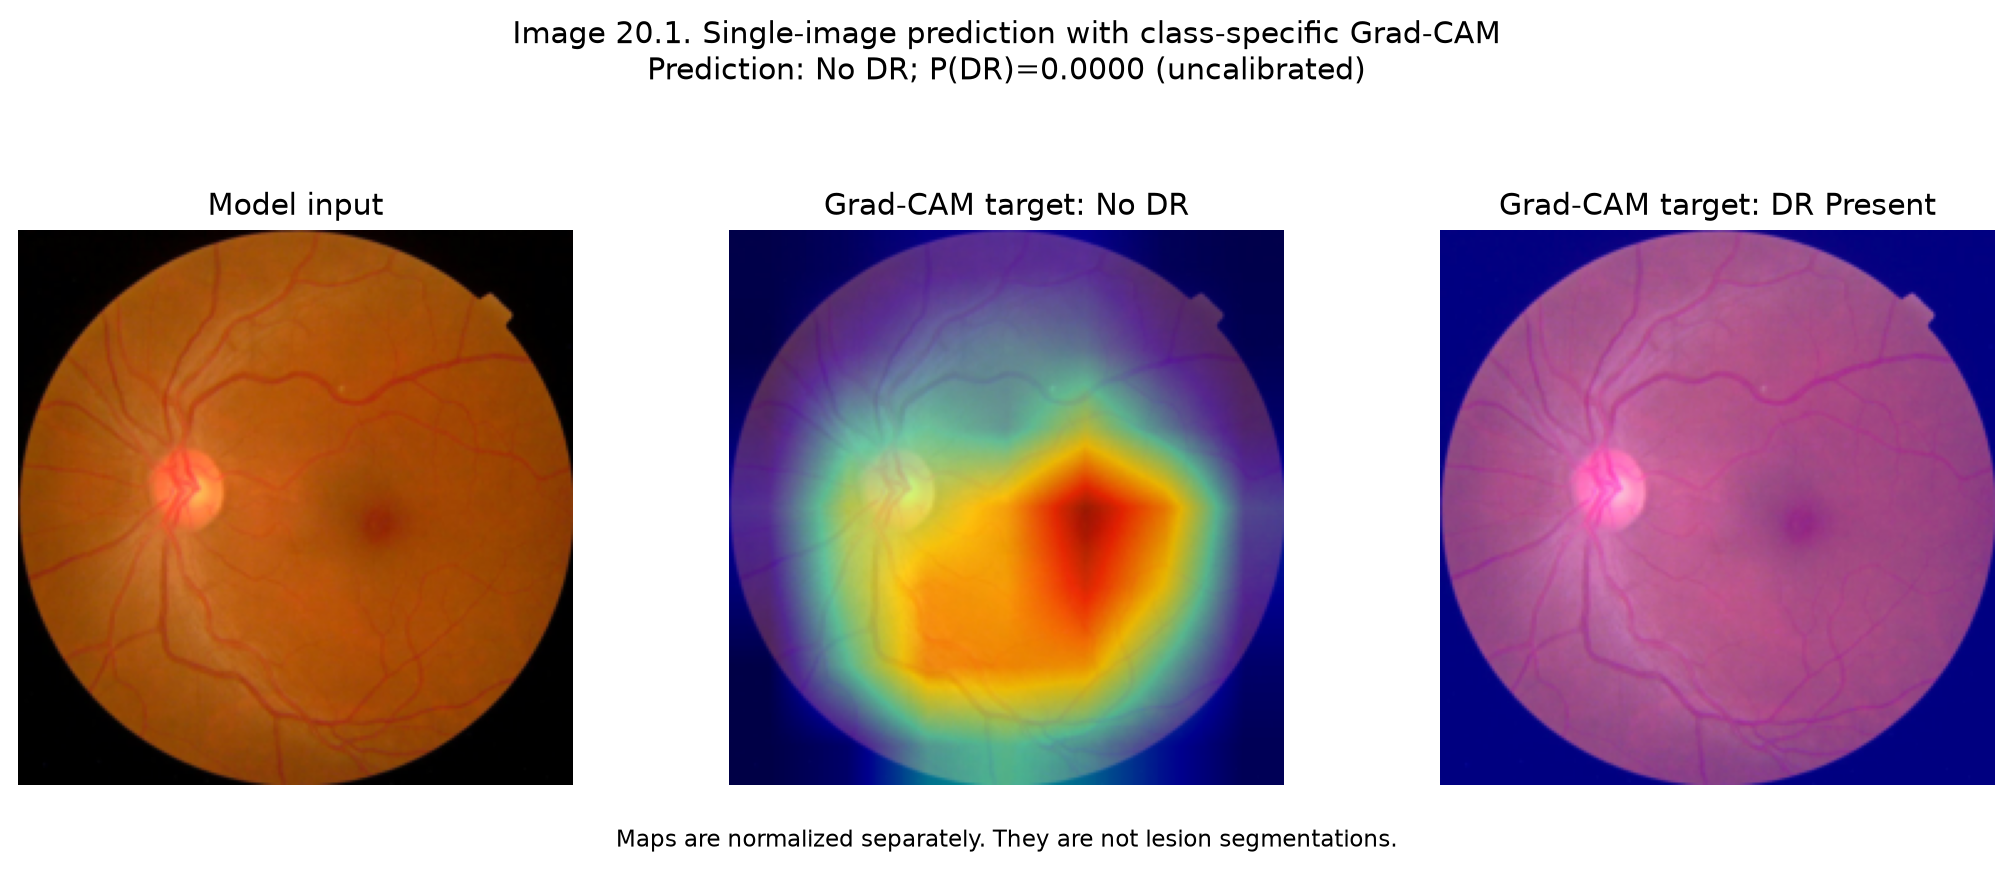

In [5]:
panel_path = output_dir / "image_20_1_single_image_prediction.png"
save_explanation_panel(
    predictor, image_path, panel_path,
    title="Image 20.1. Single-image prediction with class-specific Grad-CAM",
    subtitle=f"Prediction: {result['predicted_class']}; P(DR)={result['dr_probability']:.4f} (uncalibrated)",
)
display(DisplayImage(filename=str(panel_path), width=1100))


## Saved outputs and interpretation

The CSV, JSON, and numbered image are in `outputs/single_image_demo/`. Re-running the notebook replaces this demonstration's outputs. The JSON includes model and configuration fingerprints for reproducibility.

The heatmaps describe sensitivity of class logits to the final convolutional features. They are not lesion masks, and red regions do not independently establish disease. The probability-like numbers are model scores, not calibrated clinical risk estimates.

For a command-line demonstration:

```bash
.venv/bin/python3 scripts/predict_image.py --image path/to/fundus.png
```
